# **Import Required Libraries**

In [4]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Regular expressions for text cleaning
import re

# NLP libraries
import nltk

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Classification models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [5]:
print("Libraries imported successfully!")

Libraries imported successfully!


# **Load the Dataset**

In [6]:
import pandas as pd

df = pd.read_csv("/content/spam.csv",encoding = "latin-1")

In [7]:
df

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


# **check number of Rows and columns**

In [8]:
df.shape

(5572, 5)

# **check the column Names**

In [9]:
df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

# **check the datatypes**

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


# **Display First 5 Records**

In [11]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# **Remove Unnamed: 2, Unnamed: 3, Unnamed: 4**

In [12]:
df.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1, inplace=True)

In [13]:
df.columns

Index(['v1', 'v2'], dtype='object')

In [14]:
df

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


# **check missing values**

In [15]:
df.isnull().sum()

,0
v1,0
v2,0


# **check duplicate Values**

In [16]:
df.duplicated().sum()

np.int64(403)

# **display duplicate rows**

In [17]:
df[df.duplicated()]

,v1,v2
102,ham,As per your request 'Melle Melle (Oru Minnamin...
153,ham,As per your request 'Melle Melle (Oru Minnamin...
206,ham,"As I entered my cabin my PA said, '' Happy B'd..."
222,ham,"Sorry, I'll call later"
325,ham,No calls..messages..missed calls
...,...,...
5524,spam,You are awarded a SiPix Digital Camera! call 0...
5535,ham,"I know you are thinkin malaria. But relax, chi..."
5539,ham,Just sleeping..and surfing
5553,ham,Hahaha..use your brain dear


# **check unique values**

In [18]:
df['v1'].unique()

array(['ham', 'spam'], dtype=object)

# **count Ham and Spam**

In [19]:
df['v1'].value_counts()

,count
v1,
ham,4825
spam,747


# **check Basic dataset information**

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


# **Total Number of Messages**

In [21]:
total_messages = len(df)

print("Total messages:", total_messages)

Total messages: 5572


# **Number of Spam Messages**

In [22]:
spam_messages = (df['v1'] == 'spam').sum()

print("Number of spam messages:",spam_messages)

Number of spam messages: 747


# **Number of Ham Messages**

In [23]:
ham_messages = (df['v1'] == 'ham').sum()

print("Number of ham messages:", ham_messages)

Number of ham messages: 4825


# **Spam Percentage**

In [24]:
spam_percentage = (spam_messages/total_messages)*100

print("Spam percentage:", spam_percentage)

Spam percentage: 13.406317300789663


In [25]:
print("Spam percentage:", round(spam_percentage,2), "%")

Spam percentage: 13.41 %


# **Ham Percentage**

In [26]:
ham_percentage = (ham_messages / total_messages) * 100

print("Ham percentage:", round(ham_percentage, 2), "%")

Ham percentage: 86.59 %


# **check duplicate messages**

In [27]:
duplicate_messages = df.duplicated().sum()

print("Duplicate messages:",duplicate_messages)

Duplicate messages: 403


In [28]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


# **Check Missing Values**

In [29]:
missing_values = df.isnull().sum()

print(missing_values)

v1    0
v2    0
dtype: int64


# **Check Message Length**

In [30]:
df['message_length'] = df['v2'].str.len()

In [31]:
df[['v1','v2','message_length']].head()

,v1,v2,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


# **Average Message Length**

In [32]:
average_length = df['message_length'].mean()

print("Average message length:", round(average_length,2))

Average message length: 80.12


# **Minimum Message Length**

In [33]:
minimum_length = df['message_length'].min()

print("Minimum message length:", minimum_length)

Minimum message length: 2


# **Maximum Message Length**

In [34]:
maximum_length = df['message_length'].max()

print("Maximum message length:", maximum_length)

Maximum message length: 910


# **Message Length for Spam and Ham Seperately**

In [35]:
df.groupby('v1')['message_length'].mean()

,message_length
v1,
ham,71.023627
spam,138.866131


# **summary of Spam vs Ham**

In [36]:
df['v1'].value_counts()

,count
v1,
ham,4825
spam,747


# **Visualize Ham vs Spam**

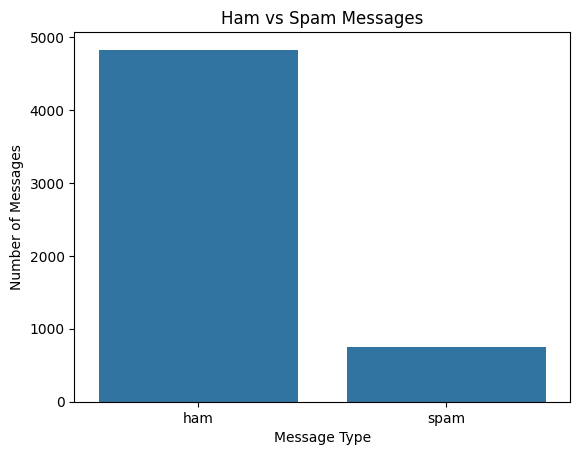

In [37]:
sns.countplot(x='v1', data=df)

plt.title('Ham vs Spam Messages')
plt.xlabel('Message Type')
plt.ylabel('Number of Messages')

plt.show()

# **Rename the Columns**

In [38]:
df.rename(columns = {
    'v1' : 'label',
    'v2' : 'message'
},inplace = True)

In [39]:
df.columns

Index(['label', 'message', 'message_length'], dtype='object')

# **Handle Missing Values**

In [40]:
df.isnull().sum()

,0
label,0
message,0
message_length,0


In [41]:
df.drop(['message_length'], axis=1, inplace=True)

In [42]:
df.columns

Index(['label', 'message'], dtype='object')

# **NLP DATA PREPROCESSING**

# **Convert Labels into Numbers**

In [43]:
df['label'].unique()

array(['ham', 'spam'], dtype=object)

In [44]:
df['label'] = df['label'].map({
    'ham': 0,
    'spam':1
})

In [45]:
df['label'].value_counts()

,count
label,
0,4825
1,747


# **Convert Text to LowerCase**

In [46]:
print(df['message'].iloc[0])

Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


In [47]:
df['message']=df['message'].str.lower()

In [48]:
print(df['message'].iloc[0])

go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...


# **Remove URLs**

In [49]:
import re

def remove_urls(text):
  text = re.sub(r'http\S+|www\S+|https\S+', '', text)
  return text

In [50]:
df['message'] = df['message'].apply(remove_urls)

In [51]:
print(df['message'].head())

0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: message, dtype: object


# **Remove Email Addresses**

In [52]:
def remove_emails(text):
  text = re.sub(r'\S+@\S+', '', text)
  return text

In [53]:
df['message'] = df['message'].apply(remove_emails)

# **Remove Special characters**

In [54]:
def remove_special_characters(text):
  text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
  return text

In [55]:
df['message'] = df['message'].apply(remove_special_characters)

# **TOKENIZATION**

In [56]:
from nltk.tokenize import word_tokenize

In [57]:
import nltk

nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [58]:
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [59]:
from nltk.tokenize import word_tokenize

df['tokens'] = df['message'].apply(word_tokenize)

In [60]:
df[['message', 'tokens']].head()

,message,tokens
0,go until jurong point crazy available only in ...,"[go, until, jurong, point, crazy, available, o..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in 2 a wkly comp to win fa cup fina...,"[free, entry, in, 2, a, wkly, comp, to, win, f..."
3,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t..."
4,nah i dont think he goes to usf he lives aroun...,"[nah, i, dont, think, he, goes, to, usf, he, l..."


# **Remove Stopwords**

In [61]:
from nltk.corpus import stopwords

In [62]:
stop_words = set(stopwords.words('english'))

In [63]:
def remove_stopwords(tokens):
  return [word for word in tokens if word not in stop_words]

In [64]:
df['tokens_without_stopwords'] = df['tokens'].apply(remove_stopwords)

In [65]:
df[['tokens','tokens_without_stopwords']].head()

,tokens,tokens_without_stopwords
0,"[go, until, jurong, point, crazy, available, o...","[go, jurong, point, crazy, available, bugis, n..."
1,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,"[free, entry, in, 2, a, wkly, comp, to, win, f...","[free, entry, 2, wkly, comp, win, fa, cup, fin..."
3,"[u, dun, say, so, early, hor, u, c, already, t...","[u, dun, say, early, hor, u, c, already, say]"
4,"[nah, i, dont, think, he, goes, to, usf, he, l...","[nah, dont, think, goes, usf, lives, around, t..."


# **Stemming**

# PorterStemmer

In [66]:
from nltk.stem import PorterStemmer

In [67]:
stemmer = PorterStemmer()

In [68]:
def stemming(tokens):
  return [stemmer.stem(word) for word in tokens]

In [69]:
df['stemmed_words'] = df['tokens_without_stopwords'].apply(stemming)

In [70]:
df[['tokens_without_stopwords', 'stemmed_words']].head()

,tokens_without_stopwords,stemmed_words
0,"[go, jurong, point, crazy, available, bugis, n...","[go, jurong, point, crazi, avail, bugi, n, gre..."
1,"[ok, lar, joking, wif, u, oni]","[ok, lar, joke, wif, u, oni]"
2,"[free, entry, 2, wkly, comp, win, fa, cup, fin...","[free, entri, 2, wkli, comp, win, fa, cup, fin..."
3,"[u, dun, say, early, hor, u, c, already, say]","[u, dun, say, earli, hor, u, c, alreadi, say]"
4,"[nah, dont, think, goes, usf, lives, around, t...","[nah, dont, think, goe, usf, live, around, tho..."


# **Lemmatization**

In [71]:
from nltk.stem import WordNetLemmatizer

In [72]:
lemmatizer = WordNetLemmatizer()

In [73]:
def lemmatization(tokens):
  return [lemmatizer.lemmatize(word) for word in tokens]

In [74]:
df['lemmatized_words'] = df['tokens_without_stopwords'].apply(lemmatization)

In [75]:
df[['tokens_without_stopwords', 'lemmatized_words']].head()

,tokens_without_stopwords,lemmatized_words
0,"[go, jurong, point, crazy, available, bugis, n...","[go, jurong, point, crazy, available, bugis, n..."
1,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,"[free, entry, 2, wkly, comp, win, fa, cup, fin...","[free, entry, 2, wkly, comp, win, fa, cup, fin..."
3,"[u, dun, say, early, hor, u, c, already, say]","[u, dun, say, early, hor, u, c, already, say]"
4,"[nah, dont, think, goes, usf, lives, around, t...","[nah, dont, think, go, usf, life, around, though]"


# **TF - IDF**

# create a final clean text

In [76]:
df['clean_text'] = df['lemmatized_words'].apply(
    lambda words: ' '.join(words)
)

In [77]:
df[['message', 'clean_text']].head()

,message,clean_text
0,go until jurong point crazy available only in ...,go jurong point crazy available bugis n great ...
1,ok lar joking wif u oni,ok lar joking wif u oni
2,free entry in 2 a wkly comp to win fa cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,u dun say so early hor u c already then say,u dun say early hor u c already say
4,nah i dont think he goes to usf he lives aroun...,nah dont think go usf life around though


# **TEXT FEATURE EXTRACTION**

Bag of Words (BoW)

In [78]:
from sklearn.feature_extraction.text import CountVectorizer

In [79]:
bow_vectorizer = CountVectorizer()

In [80]:
X_bow = bow_vectorizer.fit_transform(df['clean_text'])

In [81]:
X_bow.shape

(5572, 8702)

In [82]:
bow_vectorizer.get_feature_names_out()

array(['008704050406', '0089my', '0121', ..., 'zoom', 'zouk', 'zyada'],
      dtype=object)

In [83]:
bow_df = pd.DataFrame(
    X_bow.toarray(),
    columns = bow_vectorizer.get_feature_names_out()
)

bow_df.head()

,008704050406,0089my,0121,01223585236,01223585334,0125698789,02,020603,0207,02070836089,...,zebra,zed,zero,zhong,zindgi,zoe,zogtorius,zoom,zouk,zyada
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# **TF-IDF**

In [84]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [85]:
tfidf_vectorizer = TfidfVectorizer()

In [86]:
X_tfidf = tfidf_vectorizer.fit_transform(df['clean_text'])

In [87]:
X_tfidf.shape

(5572, 8702)

In [88]:
tfidf_vectorizer.get_feature_names_out()

array(['008704050406', '0089my', '0121', ..., 'zoom', 'zouk', 'zyada'],
      dtype=object)

In [89]:
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

tfidf_df.head()

,008704050406,0089my,0121,01223585236,01223585334,0125698789,02,020603,0207,02070836089,...,zebra,zed,zero,zhong,zindgi,zoe,zogtorius,zoom,zouk,zyada
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# **Word N-Grams**

# **unigram**

In [90]:
unigram_vectorizer = TfidfVectorizer(
    ngram_range=(1,1)
)

In [91]:
X_unigram = unigram_vectorizer.fit_transform(df['clean_text'])

In [92]:
X_unigram.shape

(5572, 8702)

# **Bigram**

In [93]:
bigram_vectorizer = TfidfVectorizer(
    ngram_range = (2,2)
)

In [94]:
X_bigram = bigram_vectorizer.fit_transform(df['clean_text'])

In [95]:
X_bigram.shape

(5572, 31303)

In [96]:
bigram_vectorizer.get_feature_names_out()[:20]

array(['008704050406 sp', '0089my last', '0121 2025050', '01223585236 xx',
       '01223585334 cum', '0125698789 ring', '02 user', '020603 2nd',
       '0207 153', '02072069400 bx', '02073162414 cost',
       '02085076972 reply', '020903 2nd', '021 3680', '021 3680offer',
       '050703 tcsbcm4235wc1n3xx', '06 good', '07046744435 arrange',
       '07090298926 reschedule', '07099833605 reschedule'], dtype=object)

# **Unigram + Bigram**

In [97]:
tfidf_uni_bigram = TfidfVectorizer(
    ngram_range = (1,2)
)

In [98]:
X_uni_bigram = tfidf_uni_bigram.fit_transform(df['clean_text'])

In [99]:
X_uni_bigram.shape

(5572, 40005)

# **Trigram**

In [100]:
trigram_vectorizer = TfidfVectorizer(
    ngram_range = (3,3)
)

In [101]:
X_trigram = trigram_vectorizer.fit_transform(df['clean_text'])

In [102]:
X_trigram.shape

(5572, 31306)

# **Split Dataset**

In [103]:
X = tfidf_vectorizer.fit_transform(df['clean_text'])
y = df['label']

In [104]:
from sklearn.model_selection import train_test_split

split into 80% training and 20% testing

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

check the train data size

In [106]:
X_train.shape

(4457, 8702)

check the test data size

In [107]:
X_test.shape

(1115, 8702)

check the labels

In [108]:
y_train.value_counts()

,count
label,
0,3859
1,598


In [109]:
y_test.value_counts()

,count
label,
0,966
1,149


# **ALGORITHMS**

# **Multinomial Naive Bayes**

In [110]:
from sklearn.naive_bayes import MultinomialNB

In [111]:
from sklearn.metrics import confusion_matrix

In [112]:
from sklearn.metrics import precision_score

In [113]:
from sklearn.metrics import recall_score

In [114]:
from sklearn.metrics import f1_score

In [115]:
nb_model = MultinomialNB()

In [116]:
nb_model.fit(X_train, y_train)

MultinomialNB()

In [117]:
y_preb_nb = nb_model.predict(X_test)

In [118]:
y_preb_nb[:20]

array([0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [119]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

# Display first 20 predictions
y_pred_nb[:20]

array([0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [120]:
from sklearn.metrics import accuracy_score

accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", accuracy_nb)

Naive Bayes Accuracy: 0.9632286995515695


In [121]:
print("Naive Bayes Accuracy:", round(accuracy_nb * 100, 2), "%")

Naive Bayes Accuracy: 96.32 %


In [122]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

print(cm_nb)

[[966   0]
 [ 41 108]]


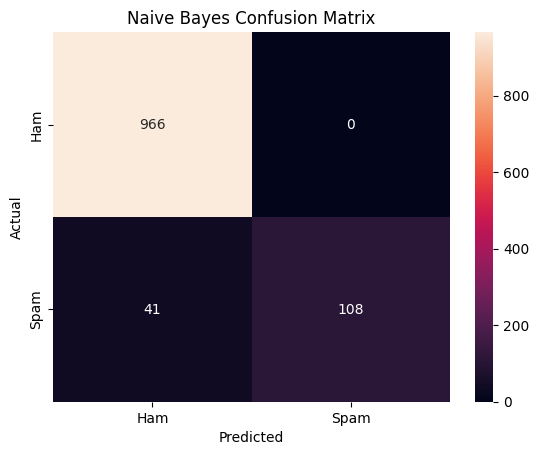

In [123]:
sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

In [124]:
precision_nb = precision_score(y_test, y_pred_nb)

print("Naive Bayes Precision:", round(precision_nb, 4))

Naive Bayes Precision: 1.0


In [125]:
recall_nb = recall_score(y_test, y_pred_nb)

print("Naive Bayes Recall:", round(recall_nb, 4))

Naive Bayes Recall: 0.7248


In [126]:
f1_nb = f1_score(y_test, y_pred_nb)

print("Naive Bayes F1-Score:", round(f1_nb, 4))

Naive Bayes F1-Score: 0.8405


In [127]:
print("Naive Bayes Classification Report")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Ham', 'Spam']
))

Naive Bayes Classification Report
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.72      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



# **Logistic Regression**

In [128]:
from sklearn.linear_model import LogisticRegression

In [129]:
lr_model = LogisticRegression(max_iter=1000)

In [130]:
lr_model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [131]:
y_pred_lr = lr_model.predict(X_test)

In [132]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(accuracy_lr * 100, 2), "%")

Logistic Regression Accuracy: 94.8 %


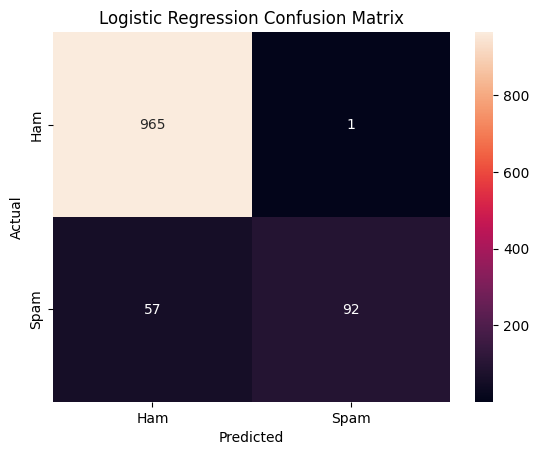

In [133]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [134]:
precision_lr = precision_score(y_test, y_pred_lr)

print("Logistic Regression Precision:", round(precision_lr, 4))

Logistic Regression Precision: 0.9892


In [135]:
recall_lr = recall_score(y_test, y_pred_lr)

print("Logistic Regression Recall:", round(recall_lr, 4))

Logistic Regression Recall: 0.6174


In [136]:
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression F1-Score:", round(f1_lr, 4))

Logistic Regression F1-Score: 0.7603


In [137]:
print("Logistic Regression Classification Report")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['Ham', 'Spam']
))

Logistic Regression Classification Report
              precision    recall  f1-score   support

         Ham       0.94      1.00      0.97       966
        Spam       0.99      0.62      0.76       149

    accuracy                           0.95      1115
   macro avg       0.97      0.81      0.87      1115
weighted avg       0.95      0.95      0.94      1115



# **Linear SVM**

In [138]:
from sklearn.svm import LinearSVC

In [139]:
svm_model = LinearSVC()

In [140]:
svm_model.fit(X_train,y_train)

LinearSVC()

In [141]:
y_pred_svm = svm_model.predict(X_test)

In [142]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", round(accuracy_svm * 100, 2), "%")

SVM Accuracy: 97.94 %


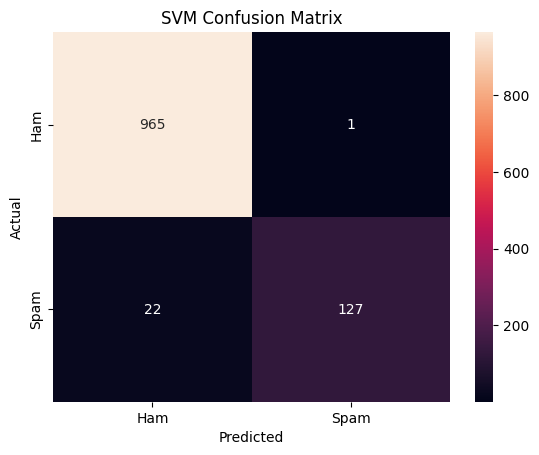

In [143]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

In [144]:
precision_svm = precision_score(y_test, y_pred_svm)

print("SVM Precision:", round(precision_svm, 4))

SVM Precision: 0.9922


In [145]:
recall_svm = recall_score(y_test, y_pred_svm)

print("SVM Recall:", round(recall_svm, 4))

SVM Recall: 0.8523


In [146]:
f1_svm = f1_score(y_test, y_pred_svm)

print("SVM F1-Score:", round(f1_svm, 4))

SVM F1-Score: 0.917


In [147]:
print("SVM Classification Report")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=['Ham', 'Spam']
))

SVM Classification Report
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.99      0.85      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



# **Random** **Forest**

In [148]:
from sklearn.ensemble import RandomForestClassifier

In [149]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [150]:
rf_model.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

In [151]:
y_pred_rf = rf_model.predict(X_test)

In [152]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(accuracy_rf * 100, 2), "%")

Random Forest Accuracy: 97.58 %


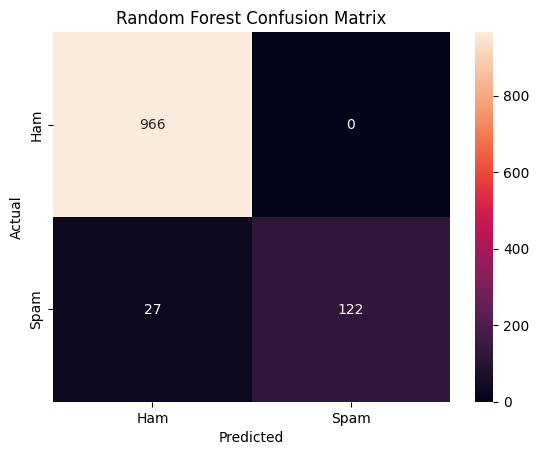

In [153]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

In [154]:
precision_rf = precision_score(y_test, y_pred_rf)

print("Random Forest Precision:", round(precision_rf, 4))

Random Forest Precision: 1.0


In [155]:
recall_rf = recall_score(y_test, y_pred_rf)

print("Random Forest Recall:", round(recall_rf, 4))

Random Forest Recall: 0.8188


In [156]:
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest F1-Score:", round(f1_rf, 4))

Random Forest F1-Score: 0.9004


In [157]:
print("Random Forest Classification Report")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Ham', 'Spam']
))

Random Forest Classification Report
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       966
        Spam       1.00      0.82      0.90       149

    accuracy                           0.98      1115
   macro avg       0.99      0.91      0.94      1115
weighted avg       0.98      0.98      0.97      1115



# **XGBoost**

In [158]:
!pip install xgboost

In [159]:
from xgboost import XGBClassifier

In [160]:
xgb_model = XGBClassifier(
    n_estimators = 100,
    max_depth = 5,
    learning_rate = 0.1,
    random_state = 42,
    eval_metric = 'logloss'
)

In [161]:
xgb_model.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [162]:
y_pred_xgb = xgb_model.predict(X_test)

In [163]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", round(accuracy_xgb * 100, 2), "%")

XGBoost Accuracy: 97.13 %


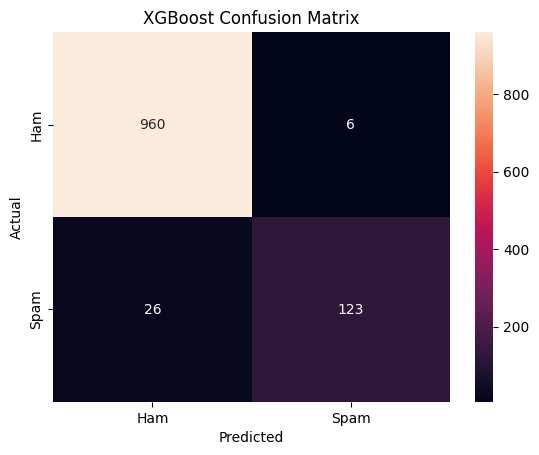

In [164]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Confusion Matrix')
plt.show()

In [165]:
precision_xgb = precision_score(y_test, y_pred_xgb)

print("XGBoost Precision:", round(precision_xgb, 4))

XGBoost Precision: 0.9535


In [166]:
recall_xgb = recall_score(y_test, y_pred_xgb)

print("XGBoost Recall:", round(recall_xgb, 4))

XGBoost Recall: 0.8255


In [167]:
f1_xgb = f1_score(y_test, y_pred_xgb)

print("XGBoost F1-Score:", round(f1_xgb, 4))

XGBoost F1-Score: 0.8849


In [168]:
print("XGBoost Classification Report")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=['Ham', 'Spam']
))

XGBoost Classification Report
              precision    recall  f1-score   support

         Ham       0.97      0.99      0.98       966
        Spam       0.95      0.83      0.88       149

    accuracy                           0.97      1115
   macro avg       0.96      0.91      0.93      1115
weighted avg       0.97      0.97      0.97      1115



# **Find Important Spam Words**

make sure your svm model is trained

In [169]:
svm_model.fit(X_train,y_train)

LinearSVC()

# **Get feature names**

In [170]:
feature_names = tfidf_vectorizer.get_feature_names_out()

# **Get SVM coeffiecients**

In [171]:
coefficients = svm_model.coef_[0]

# **Find the most important spam words/features**

In [172]:
spam_indices = coefficients.argsort()[-20:][::-1]

important_spam_words = feature_names[spam_indices]

print("Top 20 Spam Features:")

for word in important_spam_words:
  print(word)

Top 20 Spam Features:
txt
claim
service
prize
mobile
stop
ringtone
urgent
500
uk
tone
reply
88066
18
250
credit
bid
information
text
win


# **Display Spam Words with Their Scores**

In [173]:
spam_features = pd.DataFrame({
    'Feature': feature_names[spam_indices],
    'Coefficient': coefficients[spam_indices]
})

spam_features

,Feature,Coefficient
0,txt,2.385967
1,claim,2.111789
2,service,2.075793
3,prize,1.648920
4,mobile,1.627025
5,stop,1.536389
6,ringtone,1.528188
7,urgent,1.464772
8,500,1.449648
9,uk,1.433909


# **Test With New Emails**

create the prediction function

In [181]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [182]:
import nltk

nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [183]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

In [184]:
def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Convert list back to text
    text = ' '.join(tokens)

    return text

In [185]:
message = "Congratulations! You won a free iPhone. Click here to claim."

cleaned_message = preprocess_text(message)

print(cleaned_message)

congratulation free iphone click claim


In [188]:
def predict_spam(message):

    # Preprocess the new message
    cleaned_message = preprocess_text(message)

    # Convert text into TF-IDF features
    message_vector = tfidf_vectorizer.transform([cleaned_message])

    # Predict
    prediction = svm_model.predict(message_vector)[0]

    # Display result
    if prediction == 1:
        print("🔴 SPAM")
    else:
        print("🟢 NOT SPAM")

In [189]:
message = "Congratulations! You won a free iPhone. Click here to claim."

predict_spam(message)

🔴 SPAM


In [190]:
message = "Hi, are we meeting at 5 PM today?"

predict_spam(message)

🟢 NOT SPAM
